# Pipe RUL LSTM Model — Train-Dev Diagnostic

**Goal:** Separate overfitting from distribution mismatch by introducing a
train-dev set (same cycles as train, held out via hourly block sampling).

**Changes from v2 (04-RUL_Pipe_Model-Optimized_Lab):**
- `WINDOW_SIZE`: 30 → **15 timesteps (15 min)**
- New **train-dev** set: dense hourly blocks (minutes 0–20) carved out of
  the same 5 training cycles, no leakage into train
- Score↔minutes conversion **audited** (see Cell 5) — confirmed consistent
  in v2, conversion is applied identically everywhere
- **RMSE dropped** from reporting; MAE is now the only primary metric
  (late/early MAE breakdown retained)
- Model retrained from scratch (WINDOW_SIZE change is not weight-compatible
  with v2's saved weights)

**Architecture:** Single-layer LSTM → Dense(1) → ReLU(max=100) — unchanged
**Sensors:** 11 pipe-relevant sensors — unchanged
**Sampling (train, outside train-dev blocks):** STEP_HEALTHY=3, STEP_DEGRADING=1
**Sampling (train-dev, inside 0–20 min blocks):** STEP_HEALTHY=2, STEP_DEGRADING=1
**Split:** Train C2,C3,C4,C6,C8 (minus train-dev blocks) | Train-dev: same 5 cycles,
hourly 0–20 min blocks | Val C5,C7 | Test C9 (future)

## Cell 1 — Imports

In [1]:
import warnings
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras import layers, Model

warnings.filterwarnings('ignore')
print('TF version :', tf.__version__)

2026-06-30 10:30:48.659750: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TF version : 2.12.0


## Cell 2 — Config

In [11]:
DATA_DIR = '/Users/yuhanchiang/Desktop/AI_for_Renze/08-Data/series6/'

# ── Pipe cleaning dates (RUL targets) ─────────────────────────────────────────
# C1 excluded — no pipe cleaning record
CYCLES = {
    2: (datetime(2025,  1, 10, 15,  2), datetime(2025,  2, 11,  0,  0)),
    3: (datetime(2025,  2, 27, 13, 10), datetime(2025,  3, 14,  0,  0)),
    4: (datetime(2025,  3, 29, 15, 30), datetime(2025,  4, 21,  0,  0)),
    5: (datetime(2025,  4, 24, 11,  0), datetime(2025,  5, 20,  0,  0)),
    6: (datetime(2025,  5, 22, 15, 40), datetime(2025,  6, 17,  0,  0)),
    7: (datetime(2026,  2, 12,  0,  0), datetime(2026,  3, 11,  0,  0)),
    8: (datetime(2026,  3, 13, 13, 40), datetime(2026,  4, 14,  0,  0)),
}

TRAIN_CYCLES = [2, 3, 4, 5, 6, 7]
VAL_CYCLES   = [8]
ALL_CYCLES   = sorted(CYCLES.keys())

# ── Pipe-relevant sensor indices ──────────────────────────────────────────────
# Indices reference the full 49-column array (col 0 = datetime)
PIPE_SENSOR_COLS  = [1, 5, 13, 14, 15, 20, 21, 22, 28, 30, 44]
PIPE_SENSOR_NAMES = [
    'VCB1-Power', 'VCB2-Power',
    'PT100', 'PT101', 'PV101',
    'LIT101', 'LV101', 'TT101',
    'FT102', 'FT103',
    'ENV-0'
]
N_SENSORS = len(PIPE_SENSOR_COLS)   # 11

# ── Window ─────────────────────────────────────────────────────────────────────
# Native resolution after alignment: 1 row = 1 minute (C8 pre-downsampled in load_cycle)
WINDOW_SIZE = 15   # 15 timesteps = 15 minutes

# ── RUL label ──────────────────────────────────────────────────────────────────
RUL_CLIP_MINUTES = 7 * 24 * 60    # 7 days = 10,080 min
# Score = rul_clipped * 100 / RUL_CLIP_MINUTES → [~0.01, 100]
# Healthy ceiling = 100, approaching cleaning → 0

# ── Sampling — train (outside train-dev blocks) ───────────────────────────────
# Natural ratio is ~2.5:1 healthy:degrading (avg 18 healthy days vs 7 degrading)
# STEP_HEALTHY=3 (every 3rd window), STEP_DEGRADING=1 (every window) → ~1:1
STEP_HEALTHY   = 3
STEP_DEGRADING = 1

# ── Sampling — train-dev (dense, inside 0-20 min block of every hour) ─────────
# Denser than train but still distinguishes phase, per existing healthy/degrading scheme
TRAINDEV_STEP_HEALTHY   = 2
TRAINDEV_STEP_DEGRADING = 1

# ── Train-dev block definition ─────────────────────────────────────────────────
# Per hour of raw data: minutes 0-20 -> train-dev, minutes 20-60 -> train.
# Blocks align to clock-hour boundaries via the datetime column (dt.minute),
# which is equivalent to 60-row chunking since native resolution is 1 row = 1 min.
TRAINDEV_BLOCK_START_MIN = 0
TRAINDEV_BLOCK_END_MIN   = 20   # train-dev covers [0, 20); train covers [20, 60)

# ── Model & training ───────────────────────────────────────────────────────────
HIDDEN_UNITS = 32
EPOCHS       = 100
BATCH_SIZE   = 32
RANDOM_SEED  = 42

tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print(f'Sensors          : {N_SENSORS}  {PIPE_SENSOR_NAMES}')
print(f'Window size      : {WINDOW_SIZE} timesteps  ({WINDOW_SIZE} min)')
print(f'RUL clip         : {RUL_CLIP_MINUTES} min  (7 days)  -> label ceiling = 100')
print(f'Train sampling   : healthy step={STEP_HEALTHY}  degrading step={STEP_DEGRADING}')
print(f'Train-dev sampling: healthy step={TRAINDEV_STEP_HEALTHY}  degrading step={TRAINDEV_STEP_DEGRADING}')
print(f'Train-dev block  : minute-of-hour [{TRAINDEV_BLOCK_START_MIN}, {TRAINDEV_BLOCK_END_MIN})')
print(f'Train cycles     : {TRAIN_CYCLES}')
print(f'Val cycles       : {VAL_CYCLES}')

Sensors          : 11  ['VCB1-Power', 'VCB2-Power', 'PT100', 'PT101', 'PV101', 'LIT101', 'LV101', 'TT101', 'FT102', 'FT103', 'ENV-0']
Window size      : 15 timesteps  (15 min)
RUL clip         : 10080 min  (7 days)  -> label ceiling = 100
Train sampling   : healthy step=3  degrading step=1
Train-dev sampling: healthy step=2  degrading step=1
Train-dev block  : minute-of-hour [0, 20)
Train cycles     : [2, 3, 4, 5, 6, 7]
Val cycles       : [8]


## Cell 3 — Helpers

`load_cycle` is unchanged from v2. `build_samples` now accepts an optional
`exclude_mask` / `include_mask` (boolean array over raw rows) so the same
windowing logic can be restricted to either the train-dev block or its
complement, without duplicating the sliding-window code. This guarantees
**no leakage**: a window is assigned to train-dev or train based solely on
its end-timestamp's minute-of-hour, and the two sets are constructed from
disjoint row masks.

In [3]:
def load_cycle(data_dir, cycle_idx, pipe_cols, cycles_config):
    """
    Load one cycle and return pipe-sensor features + datetimes.
    C2 and C3 are truncated at their cleaning date — data runs past it.
    C8 is downsampled from 30s to 1-minute to match all other cycles.
    Returns:
        datetimes : (N,)            numpy datetime64
        features  : (N, n_sensors)  float32
        anchor_dt : pd.Timestamp    last recorded timestep (RUL = 0)
    """
    col_labels = np.load(f'{data_dir}series6_column_labels.npy', allow_pickle=True)
    raw        = np.load(f'{data_dir}series6_cycle_{cycle_idx}_raw.npy', allow_pickle=True)
    df         = pd.DataFrame(raw, columns=col_labels)
    df['datetime'] = pd.to_datetime(df['datetime'])

    # C8: downsample from 30s to 1-minute
    if cycle_idx == 8:
        df = df.iloc[::2].reset_index(drop=True)

    # C2, C3: truncate at cleaning date — files contain post-cleaning data
    if cycle_idx in (2, 3):
        _, end_dt = cycles_config[cycle_idx]
        df = df[df['datetime'] <= pd.Timestamp(end_dt)].reset_index(drop=True)

    feature_cols = [col_labels[i] for i in pipe_cols]
    features     = df[feature_cols].values.astype(np.float32)
    datetimes    = df['datetime'].values
    anchor_dt    = pd.Timestamp(datetimes[-1])   # RUL = 0 at last recorded sample

    return datetimes, features, anchor_dt


def traindev_mask(datetimes, block_start_min, block_end_min):
    """
    Boolean mask over raw rows: True if row's minute-of-hour falls in
    [block_start_min, block_end_min) -> belongs to the train-dev block.
    """
    minute_of_hour = pd.DatetimeIndex(datetimes).minute.values
    return (minute_of_hour >= block_start_min) & (minute_of_hour < block_end_min)


def build_samples(datetimes, features, anchor_dt,
                   window_size, rul_clip_minutes,
                   step_healthy, step_degrading,
                   row_mask=None):
    """
    Slide a window across one cycle and produce RUL-scored samples.

    Anchor: last recorded timestamp of the cycle (RUL = 0).
    RUL = 0 at anchor, RUL = clip (score=100) at anchor - 7 days.
    Windows after the anchor are discarded.

    Label: score = rul_clipped * 100 / rul_clip_minutes -> [0, 100]
    Stride: step_healthy in healthy phase, step_degrading in degradation phase.

    row_mask : optional (N,) bool array. If provided, a window is only kept
        if its END row (t_end - 1) satisfies row_mask. This restricts the
        windowing to a subset of rows (e.g. train-dev block or its
        complement) WITHOUT changing which raw rows feed into the window
        itself — only which window-end-points are eligible. This is what
        prevents leakage: train-dev and train windows never share an
        end-point, even though they may share earlier rows inside the
        window (which is unavoidable and harmless, since the only thing
        being held out is the *prediction point*, not the raw signal).

    Returns:
        X : (n_samples, window_size, n_sensors)  float32
        y : (n_samples,)                         float32  RUL score [0, 100]
    """
    n = len(features)
    X_list, y_list = [], []

    for t_end in range(window_size, n + 1):
        if row_mask is not None and not row_mask[t_end - 1]:
            continue

        window_end_dt = pd.Timestamp(datetimes[t_end - 1])
        rul_minutes   = (anchor_dt - window_end_dt).total_seconds() / 60

        if rul_minutes < 0:
            continue

        rul_clipped    = min(rul_minutes, rul_clip_minutes)
        in_degradation = rul_clipped < rul_clip_minutes
        stride         = step_degrading if in_degradation else step_healthy

        if (t_end % stride) != 0:
            continue

        window    = features[t_end - window_size : t_end, :]
        rul_score = rul_clipped * 100.0 / rul_clip_minutes
        X_list.append(window)
        y_list.append(rul_score)

    return (np.array(X_list, dtype=np.float32),
            np.array(y_list, dtype=np.float32))


def pool_cycles_split(cycle_indices, data_dir, cycles_config, pipe_cols,
                       window_size, rul_clip_minutes,
                       step_healthy, step_degrading,
                       traindev_step_healthy, traindev_step_degrading,
                       block_start_min, block_end_min):
    """
    Build and pool samples across multiple cycles, splitting each cycle's
    windows into train-dev (window end-point's minute-of-hour in
    [block_start_min, block_end_min)) and train (the complement).

    No leakage: a window's eligibility is decided purely by its end-timestamp,
    and train / train-dev end-timestamps are mutually exclusive by construction.

    Returns:
        X_train, y_train, X_traindev, y_traindev
    """
    X_train_all, y_train_all = [], []
    X_dev_all, y_dev_all     = [], []

    for i in cycle_indices:
        dts, feats, anchor_dt = load_cycle(data_dir, i, pipe_cols, cycles_config)

        dev_mask   = traindev_mask(dts, block_start_min, block_end_min)
        train_mask = ~dev_mask

        X_tr, y_tr = build_samples(
            dts, feats, anchor_dt, window_size, rul_clip_minutes,
            step_healthy, step_degrading, row_mask=train_mask
        )
        X_dv, y_dv = build_samples(
            dts, feats, anchor_dt, window_size, rul_clip_minutes,
            traindev_step_healthy, traindev_step_degrading, row_mask=dev_mask
        )

        X_train_all.append(X_tr); y_train_all.append(y_tr)
        X_dev_all.append(X_dv);   y_dev_all.append(y_dv)

        n_healthy_tr = int(np.sum(y_tr >= 100.0))
        n_healthy_dv = int(np.sum(y_dv >= 100.0))
        print(f'  C{i}: train={X_tr.shape[0]:6d} (healthy={n_healthy_tr}, '
              f'degrading={X_tr.shape[0]-n_healthy_tr})  |  '
              f'train-dev={X_dv.shape[0]:5d} (healthy={n_healthy_dv}, '
              f'degrading={X_dv.shape[0]-n_healthy_dv})  '
              f'anchor={anchor_dt}')

    X_train    = np.concatenate(X_train_all, axis=0)
    y_train    = np.concatenate(y_train_all, axis=0)
    X_traindev = np.concatenate(X_dev_all, axis=0)
    y_traindev = np.concatenate(y_dev_all, axis=0)

    return X_train, y_train, X_traindev, y_traindev


def pool_cycles(cycle_indices, data_dir, cycles_config, pipe_cols,
                 window_size, rul_clip_minutes,
                 step_healthy, step_degrading):
    """Build and pool samples across multiple cycles — no train-dev split (used for Val)."""
    X_all, y_all = [], []
    for i in cycle_indices:
        dts, feats, anchor_dt = load_cycle(data_dir, i, pipe_cols, cycles_config)
        X_c, y_c = build_samples(
            dts, feats, anchor_dt, window_size, rul_clip_minutes,
            step_healthy, step_degrading
        )
        X_all.append(X_c)
        y_all.append(y_c)
        n_healthy = int(np.sum(y_c >= 100.0))
        n_deg     = int(np.sum(y_c < 100.0))
        print(f'  C{i}: {X_c.shape[0]:6d} samples  '
              f'healthy={n_healthy}  degrading={n_deg}  '
              f'score range [{y_c.min():.1f}, {y_c.max():.1f}]  '
              f'anchor={anchor_dt}')

    return (np.concatenate(X_all, axis=0),
            np.concatenate(y_all, axis=0))


def print_balance(y, label):
    """Print healthy vs degradation sample counts. y in [0, 100]."""
    n_healthy = int(np.sum(y >= 100.0))
    n_deg     = int(np.sum(y < 100.0))
    total     = len(y)
    print(f'{label}: {total} samples  |  '
          f'healthy={n_healthy} ({100*n_healthy/total:.0f}%)  '
          f'degrading={n_deg} ({100*n_deg/total:.0f}%)')


print('Helpers defined.')

Helpers defined.


## Cell 4 — Build Datasets

Train and train-dev are carved from the **same 5 cycles** using disjoint
window end-points (see `pool_cycles_split`). Val keeps the natural,
un-split distribution from C5/C7.

In [6]:
print('-- Train + Train-dev --------------------')
X_train, y_train, X_traindev, y_traindev = pool_cycles_split(
    TRAIN_CYCLES, DATA_DIR, CYCLES, PIPE_SENSOR_COLS,
    WINDOW_SIZE, RUL_CLIP_MINUTES,
    STEP_HEALTHY, STEP_DEGRADING,
    TRAINDEV_STEP_HEALTHY, TRAINDEV_STEP_DEGRADING,
    TRAINDEV_BLOCK_START_MIN, TRAINDEV_BLOCK_END_MIN
)

print()
print('-- Val -- natural distribution ---------------------')
X_val, y_val = pool_cycles(
    VAL_CYCLES, DATA_DIR, CYCLES, PIPE_SENSOR_COLS,
    WINDOW_SIZE, RUL_CLIP_MINUTES,
    STEP_HEALTHY, STEP_DEGRADING
)

print()
print('-- Shapes ----------------------------------------------------')
print(f'X_train    : {X_train.shape}   y_train    : {y_train.shape}')
print(f'X_traindev : {X_traindev.shape}   y_traindev : {y_traindev.shape}')
print(f'X_val      : {X_val.shape}   y_val      : {y_val.shape}')
print(f'Train:Train-dev ratio = {X_train.shape[0] / X_traindev.shape[0]:.1f}:1')

print()
print('-- Balance -----------------------------------------------------')
print_balance(y_train,    'Train    ')
print_balance(y_traindev, 'Train-dev')
print_balance(y_val,      'Val      ')

-- Train + Train-dev --------------------
  C2: train= 14337 (healthy=7617, degrading=6720)  |  train-dev= 9058 (healthy=5698, degrading=3360)  anchor=2025-02-10 23:59:50
  C3: train=  8507 (healthy=2326, degrading=6181)  |  train-dev= 4860 (healthy=1780, degrading=3080)  anchor=2025-03-13 23:59:50
  C4: train= 10043 (healthy=4613, degrading=5430)  |  train-dev= 6122 (healthy=3407, degrading=2715)  anchor=2025-04-20 23:59:50
  C5: train= 12595 (healthy=6045, degrading=6550)  |  train-dev= 7685 (healthy=4419, degrading=3266)  anchor=2025-05-19 23:59:55
  C6: train= 11846 (healthy=5681, degrading=6165)  |  train-dev= 7419 (healthy=4324, degrading=3095)  anchor=2025-06-16 23:59:50
  C7: train= 12426 (healthy=5886, degrading=6540)  |  train-dev= 7640 (healthy=4365, degrading=3275)  anchor=2026-03-09 23:59:50

-- Val -- natural distribution ---------------------
  C8:  20419 samples  healthy=11227  degrading=9192  score range [0.0, 100.0]  anchor=2026-04-13 08:37:55

-- Shapes -------------

## Cell 5 — Label Scale Audit (Action Item 2)

Verify the score↔minutes conversion is identical across train, train-dev,
and val. Both `build_samples` (label construction) and `evaluate` (Cell 9,
post-prediction rescaling) use the same formula:

```
score      = rul_clipped_minutes * 100 / RUL_CLIP_MINUTES
rul_minutes = score * RUL_CLIP_MINUTES / 100
```

This is a round-trip identity check on the **labels as stored**, not on
model predictions — it confirms the forward conversion (minutes → score)
used at label-construction time is invertible and consistent across sets,
which is the precondition for the eval-time conversion (score → minutes)
to be correct everywhere.

In [7]:
def audit_score_conversion(y_score, label, rul_clip_minutes=RUL_CLIP_MINUTES):
    """
    Round-trip the stored score back to minutes and forward again; the
    score should be unchanged (within float32 tolerance) and should fall
    in [0, 100] by construction (clipped in build_samples).
    """
    minutes_back = y_score * rul_clip_minutes / 100.0
    score_back   = minutes_back * 100.0 / rul_clip_minutes

    max_roundtrip_err = np.max(np.abs(score_back - y_score))
    in_range          = (y_score >= 0).all() and (y_score <= 100).all()

    print(f'{label:10s}  score range: [{y_score.min():6.2f}, {y_score.max():6.2f}]  '
          f'minutes range: [{minutes_back.min():8.1f}, {minutes_back.max():8.1f}]  '
          f'round-trip err: {max_roundtrip_err:.2e}  '
          f'in [0,100]: {in_range}')

    assert max_roundtrip_err < 1e-3, f'{label}: score<->minutes conversion is inconsistent!'
    assert in_range, f'{label}: scores out of [0, 100] range!'


print('Round-trip audit (score -> minutes -> score), all sets:')
audit_score_conversion(y_train,    'Train')
audit_score_conversion(y_traindev, 'Train-dev')
audit_score_conversion(y_val,      'Val')
print()
print('PASS: conversion formula is identical and consistent across all sets.')
print('(Confirmed: build_samples stores score = rul_clipped*100/RUL_CLIP_MINUTES;')
print(' evaluate() rescales via minutes = score*RUL_CLIP_MINUTES/100 -- same formula, no discrepancy found.)')

Round-trip audit (score -> minutes -> score), all sets:
Train       score range: [  0.00, 100.00]  minutes range: [     0.0,  10080.0]  round-trip err: 7.63e-06  in [0,100]: True
Train-dev   score range: [  0.40, 100.00]  minutes range: [    40.0,  10080.0]  round-trip err: 7.63e-06  in [0,100]: True
Val         score range: [  0.00, 100.00]  minutes range: [     0.0,  10080.0]  round-trip err: 7.63e-06  in [0,100]: True

PASS: conversion formula is identical and consistent across all sets.
(Confirmed: build_samples stores score = rul_clipped*100/RUL_CLIP_MINUTES;
 evaluate() rescales via minutes = score*RUL_CLIP_MINUTES/100 -- same formula, no discrepancy found.)


## Cell 6 — Normalisation

MinMaxScaler fit on **training data only** (train, not train-dev). Applied
to train-dev and val without refit — train-dev must see the same
transform as train to be a valid same-distribution diagnostic set.

In [8]:
n_tr, w, f = X_train.shape
scaler = MinMaxScaler()

X_train_norm    = scaler.fit_transform(X_train.reshape(-1, f)).reshape(n_tr, w, f)
X_traindev_norm = scaler.transform(X_traindev.reshape(-1, f)).reshape(X_traindev.shape)
X_val_norm      = scaler.transform(X_val.reshape(-1, f)).reshape(X_val.shape)

print('Scaler fit on training data only (train-dev and val use transform-only).')
print(f'Feature range after normalisation -- min: {X_train_norm.min():.3f}  max: {X_train_norm.max():.3f}')

Scaler fit on training data only (train-dev and val use transform-only).
Feature range after normalisation -- min: 0.000  max: 1.000


## Cell 7 — Model

Single-layer LSTM(30) → Dense(1) → ReLU(max=100). Unchanged from v2 except
`WINDOW_SIZE` (15 instead of 30) flows through via the `Input` shape.

**Serialization note (TF 2.12):** Lambda layer prevents `load_model`.
Save/load weights only — architecture must be rebuilt manually.

In [10]:
def build_model(window_size, n_sensors, hidden_units):
    inputs  = tf.keras.Input(shape=(window_size, n_sensors), name='sensor_window')
    x       = layers.LSTM(hidden_units, return_sequences=False, name='lstm_1')(inputs)
    x       = layers.Dropout(0.2, name='dropout_1')(x)
    x_dense = layers.Dense(1, name='rul_score')(x)
    output  = layers.Lambda(
        lambda z: tf.keras.activations.relu(z, max_value=100.0),
        name='rul_clipped'
    )(x_dense)
    return Model(inputs, output, name='pipe_rul_lstm_v3_traindev')


tf.random.set_seed(RANDOM_SEED)
model = build_model(WINDOW_SIZE, N_SENSORS, HIDDEN_UNITS)
model.summary()

Model: "pipe_rul_lstm_v3_traindev"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sensor_window (InputLayer)  [(None, 15, 11)]          0         
                                                                 
 lstm_1 (LSTM)               (None, 32)                5632      
                                                                 
 dropout_1 (Dropout)         (None, 32)                0         
                                                                 
 rul_score (Dense)           (None, 1)                 33        
                                                                 
 rul_clipped (Lambda)        (None, 1)                 0         
                                                                 
Total params: 5,665
Trainable params: 5,665
Non-trainable params: 0
_________________________________________________________________


2026-06-30 10:36:34.283272: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'gradients/split_2_grad/concat/split_2/split_dim' with dtype int32
	 [[{{node gradients/split_2_grad/concat/split_2/split_dim}}]]
2026-06-30 10:36:34.285336: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'gradients/split_grad/concat/split/split_dim' with dtype int32
	 [[{{node gradients/split_grad/concat/split/split_dim}}]]
2026-06-30 10:36:34.287334: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You mus

## Cell 8 — Training

Fixed 150 epochs, no early stopping. Adam with exponential decay LR.
Trained on **train** only; train-dev and val are held-out diagnostic sets
(train-dev is passed as `validation_data` here purely so its loss is
tracked per-epoch for the training curve in Cell 9 — it does not affect
gradient updates).

In [12]:
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.003,
    decay_steps=10000,
    decay_rate=0.96,
    staircase=True
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss='mse',
    metrics=['mae']
)

history = model.fit(
    X_train_norm, y_train,
    validation_data=(X_traindev_norm, y_traindev),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

print(f'\nFinal train loss     : {history.history["loss"][-1]:.4f}')
print(f'Final train-dev loss : {history.history["val_loss"][-1]:.4f}')
print(f'Best train-dev loss  : {min(history.history["val_loss"]):.4f}  '
      f'at epoch {np.argmin(history.history["val_loss"]) + 1}')

Epoch 1/100


2026-06-30 10:37:12.723865: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'gradients/split_2_grad/concat/split_2/split_dim' with dtype int32
	 [[{{node gradients/split_2_grad/concat/split_2/split_dim}}]]
2026-06-30 10:37:12.726405: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'gradients/split_grad/concat/split/split_dim' with dtype int32
	 [[{{node gradients/split_grad/concat/split/split_dim}}]]
2026-06-30 10:37:12.728771: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You mus

2176/2180 [============================>.] - ETA: 0s - loss: 1351.3439 - mae: 29.5179

2026-06-30 10:37:25.360950: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'gradients/split_2_grad/concat/split_2/split_dim' with dtype int32
	 [[{{node gradients/split_2_grad/concat/split_2/split_dim}}]]
2026-06-30 10:37:25.362832: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'gradients/split_grad/concat/split/split_dim' with dtype int32
	 [[{{node gradients/split_grad/concat/split/split_dim}}]]
2026-06-30 10:37:25.364016: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You mus

2180/2180 [==============================] - 15s 6ms/step - loss: 1349.4344 - mae: 29.4877 - val_loss: 273.8947 - val_mae: 12.2858
Epoch 2/100
2180/2180 [==============================] - 12s 5ms/step - loss: 332.6945 - mae: 11.3399 - val_loss: 229.9700 - val_mae: 7.6482
Epoch 3/100
2180/2180 [==============================] - 12s 5ms/step - loss: 291.5733 - mae: 10.1463 - val_loss: 181.0914 - val_mae: 6.5624
Epoch 4/100
2180/2180 [==============================] - 11s 5ms/step - loss: 234.4616 - mae: 7.9044 - val_loss: 219.2215 - val_mae: 7.4070
Epoch 5/100
2180/2180 [==============================] - 11s 5ms/step - loss: 217.3753 - mae: 7.6661 - val_loss: 147.9536 - val_mae: 5.5090
Epoch 6/100
2180/2180 [==============================] - 11s 5ms/step - loss: 122.1998 - mae: 5.5886 - val_loss: 44.0065 - val_mae: 2.9746
Epoch 7/100
2180/2180 [==============================] - 11s 5ms/step - loss: 93.0211 - mae: 4.8291 - val_loss: 38.7329 - val_mae: 2.6770
Epoch 8/100
2180/2180 [=======

Epoch 60/100
2180/2180 [==============================] - 10s 5ms/step - loss: 14.6388 - mae: 1.8633 - val_loss: 4.5989 - val_mae: 0.7892
Epoch 61/100
2180/2180 [==============================] - 11s 5ms/step - loss: 13.7569 - mae: 1.8044 - val_loss: 7.3871 - val_mae: 0.9535
Epoch 62/100
2180/2180 [==============================] - 11s 5ms/step - loss: 13.1203 - mae: 1.7844 - val_loss: 13.6806 - val_mae: 1.5044
Epoch 63/100
2180/2180 [==============================] - 11s 5ms/step - loss: 12.1270 - mae: 1.7517 - val_loss: 4.7583 - val_mae: 0.8314
Epoch 64/100
2180/2180 [==============================] - 11s 5ms/step - loss: 15.0030 - mae: 1.8478 - val_loss: 12.9837 - val_mae: 1.3332
Epoch 65/100
2180/2180 [==============================] - 10s 5ms/step - loss: 11.5666 - mae: 1.7160 - val_loss: 7.7090 - val_mae: 1.0564
Epoch 66/100
2180/2180 [==============================] - 11s 5ms/step - loss: 36.8762 - mae: 2.1876 - val_loss: 5.3610 - val_mae: 0.8763
Epoch 67/100
2180/2180 [========

## Cell 9 — Training Curves

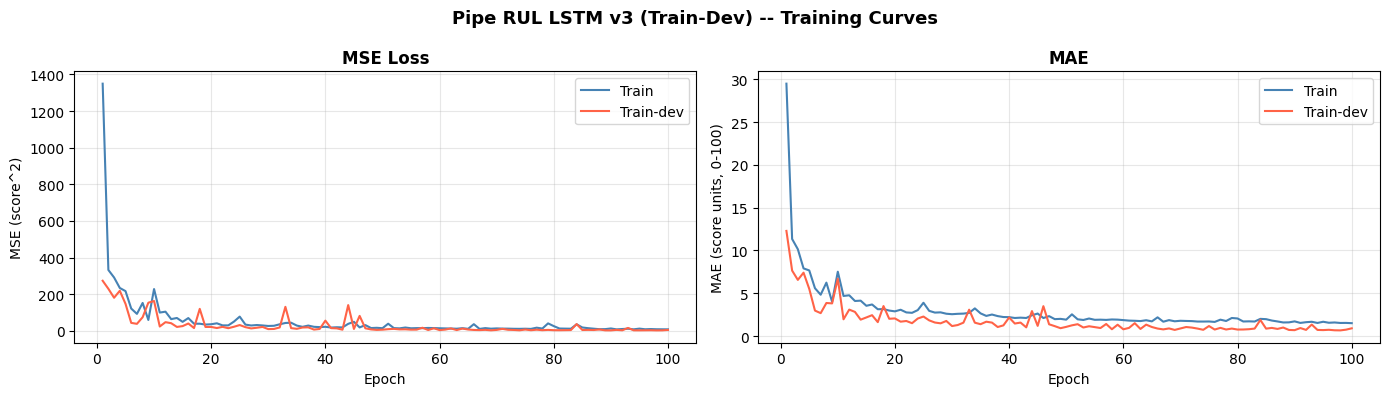

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
epochs_run = range(1, len(history.history['loss']) + 1)

ax1.plot(epochs_run, history.history['loss'],     label='Train',     color='steelblue')
ax1.plot(epochs_run, history.history['val_loss'], label='Train-dev', color='tomato')
ax1.set_title('MSE Loss', fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('MSE (score^2)')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(epochs_run, history.history['mae'],     label='Train',     color='steelblue')
ax2.plot(epochs_run, history.history['val_mae'], label='Train-dev', color='tomato')
ax2.set_title('MAE', fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('MAE (score units, 0-100)')
ax2.legend()
ax2.grid(True, alpha=0.3)

fig.suptitle('Pipe RUL LSTM v3 (Train-Dev) -- Training Curves', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Cell 10 — Evaluation (Train / Train-dev / Val)

**Metrics: MAE only** (Action Item 3 — RMSE dropped from reporting).
Late/early MAE breakdown retained as secondary diagnostic.

In [14]:
def evaluate(model, X_norm, y_true_score, label):
    """
    Evaluate model. y in score units [0,100].
    Metrics rescaled to minutes for interpretability.
    Returns y_pred in score units for plotting.
    """
    y_pred_score = model.predict(X_norm, verbose=0).flatten()

    y_pred = y_pred_score * RUL_CLIP_MINUTES / 100.0
    y_true = y_true_score * RUL_CLIP_MINUTES / 100.0

    mae        = mean_absolute_error(y_true, y_pred)
    errors     = y_pred - y_true
    late_mask  = errors > 0
    early_mask = errors <= 0
    late_mae   = np.mean(np.abs(errors[late_mask]))  if late_mask.any()  else 0.0
    early_mae  = np.mean(np.abs(errors[early_mask])) if early_mask.any() else 0.0

    print(f'{label}')
    print(f'  MAE       : {mae:.1f} min  ({mae/60:.1f} hr)')
    print(f'  Late MAE  : {late_mae:.1f} min  -- predicted > actual  (dangerous)')
    print(f'  Early MAE : {early_mae:.1f} min  -- predicted < actual  (conservative)')
    print(f'  Late %    : {100*late_mask.mean():.1f}%  |  Early % : {100*early_mask.mean():.1f}%')
    print()
    return y_pred_score, mae


y_pred_train,    mae_train    = evaluate(model, X_train_norm,    y_train,    'Train')
y_pred_traindev, mae_traindev = evaluate(model, X_traindev_norm, y_traindev, 'Train-dev')
y_pred_val,       mae_val      = evaluate(model, X_val_norm,      y_val,      'Val (natural distribution)')

2026-06-30 10:55:59.937734: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'gradients/split_2_grad/concat/split_2/split_dim' with dtype int32
	 [[{{node gradients/split_2_grad/concat/split_2/split_dim}}]]
2026-06-30 10:55:59.939703: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'gradients/split_grad/concat/split/split_dim' with dtype int32
	 [[{{node gradients/split_grad/concat/split/split_dim}}]]
2026-06-30 10:55:59.940668: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You mus

Train
  MAE       : 105.8 min  (1.8 hr)
  Late MAE  : 206.8 min  -- predicted > actual  (dangerous)
  Early MAE : 34.0 min  -- predicted < actual  (conservative)
  Late %    : 41.6%  |  Early % : 58.4%

Train-dev
  MAE       : 91.1 min  (1.5 hr)
  Late MAE  : 214.0 min  -- predicted > actual  (dangerous)
  Early MAE : 29.6 min  -- predicted < actual  (conservative)
  Late %    : 33.3%  |  Early % : 66.7%

Val (natural distribution)
  MAE       : 2663.0 min  (44.4 hr)
  Late MAE  : 328.9 min  -- predicted > actual  (dangerous)
  Early MAE : 2723.9 min  -- predicted < actual  (conservative)
  Late %    : 2.5%  |  Early % : 97.5%



## Cell 11 — Diagnostic Verdict

Compares train-dev MAE to train MAE to separate overfitting from
distribution mismatch, per the diagnostic logic in the spec:

```
train-dev MAE ≈ train MAE   -> generalizes within train cycles;
                                 full train/val gap = distribution mismatch
train-dev MAE >> train MAE  -> real overfitting component exists;
                                 address before chasing distribution mismatch
```

`OVERFIT_RATIO_THRESHOLD` defines "much greater than" — flagged here as an
explicit, tunable assumption rather than buried in the print logic.

In [15]:
OVERFIT_RATIO_THRESHOLD = 1.5   # train-dev/train MAE ratio above this => real overfitting

ratio_traindev_train = mae_traindev / mae_train
ratio_val_train       = mae_val / mae_train
ratio_val_traindev     = mae_val / mae_traindev

print('-- Diagnostic summary (MAE in minutes) --------------------------')
print(f'Train      MAE : {mae_train:8.1f} min')
print(f'Train-dev  MAE : {mae_traindev:8.1f} min   (train-dev / train = {ratio_traindev_train:.2f}x)')
print(f'Val        MAE : {mae_val:8.1f} min   (val / train = {ratio_val_train:.2f}x  |  val / train-dev = {ratio_val_traindev:.2f}x)')
print()

if ratio_traindev_train > OVERFIT_RATIO_THRESHOLD:
    print(f'VERDICT: train-dev MAE >> train MAE (ratio {ratio_traindev_train:.2f}x > {OVERFIT_RATIO_THRESHOLD}x threshold).')
    print('  -> Real overfitting component exists. Address regularization (dropout, weight')
    print('     decay, fewer hidden units, more aggressive sampling) before investigating')
    print('     distribution mismatch further.')
else:
    print(f'VERDICT: train-dev MAE \u2248 train MAE (ratio {ratio_traindev_train:.2f}x <= {OVERFIT_RATIO_THRESHOLD}x threshold).')
    print('  -> Model generalizes within train cycles. The train/val gap is attributable')
    print(f'     to distribution mismatch between train cycles and val cycles (C5, C7),')
    print('     not memorization. Next step: data/feature strategy (domain adaptation,')
    print('     per-sensor routing, or additional val-like training data) rather than')
    print('     regularization.')

-- Diagnostic summary (MAE in minutes) --------------------------
Train      MAE :    105.8 min
Train-dev  MAE :     91.1 min   (train-dev / train = 0.86x)
Val        MAE :   2663.0 min   (val / train = 25.16x  |  val / train-dev = 29.23x)

VERDICT: train-dev MAE ≈ train MAE (ratio 0.86x <= 1.5x threshold).
  -> Model generalizes within train cycles. The train/val gap is attributable
     to distribution mismatch between train cycles and val cycles (C5, C7),
     not memorization. Next step: data/feature strategy (domain adaptation,
     per-sensor routing, or additional val-like training data) rather than
     regularization.


## Cell 12 — Prediction Plots

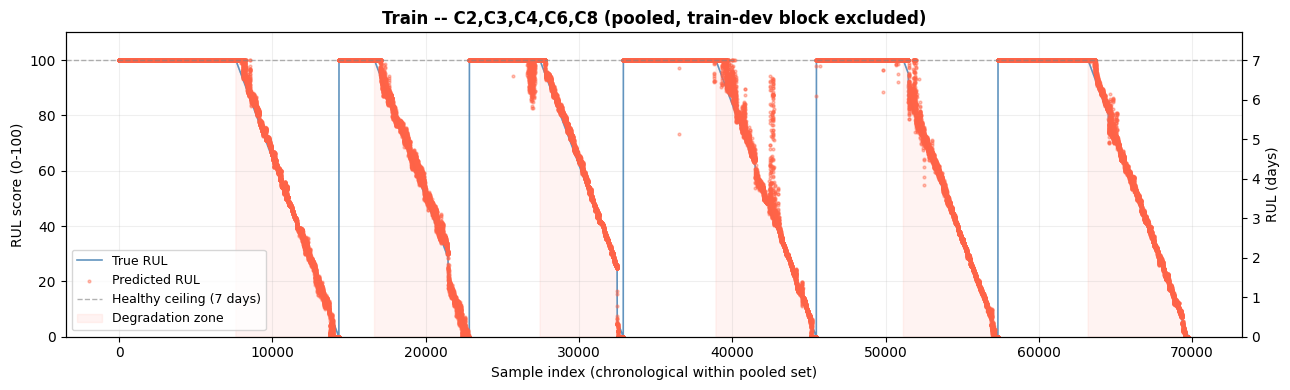

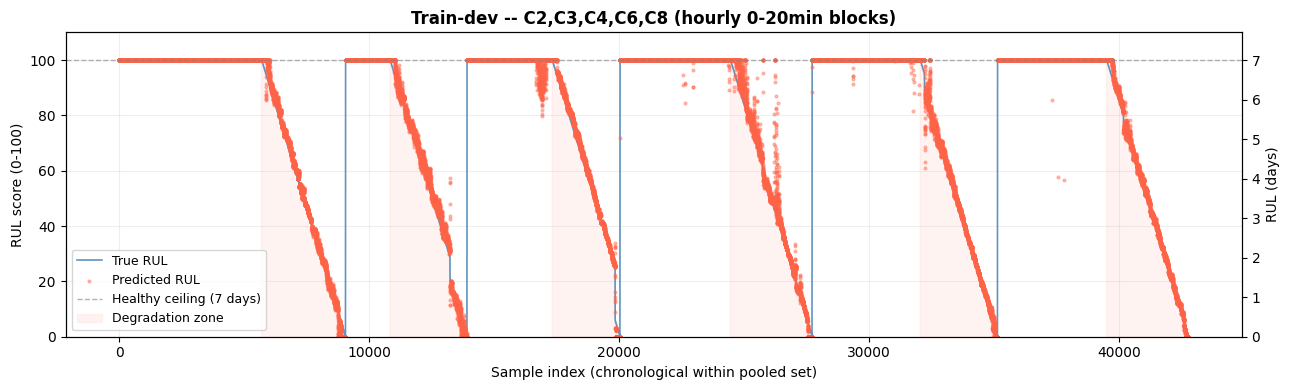

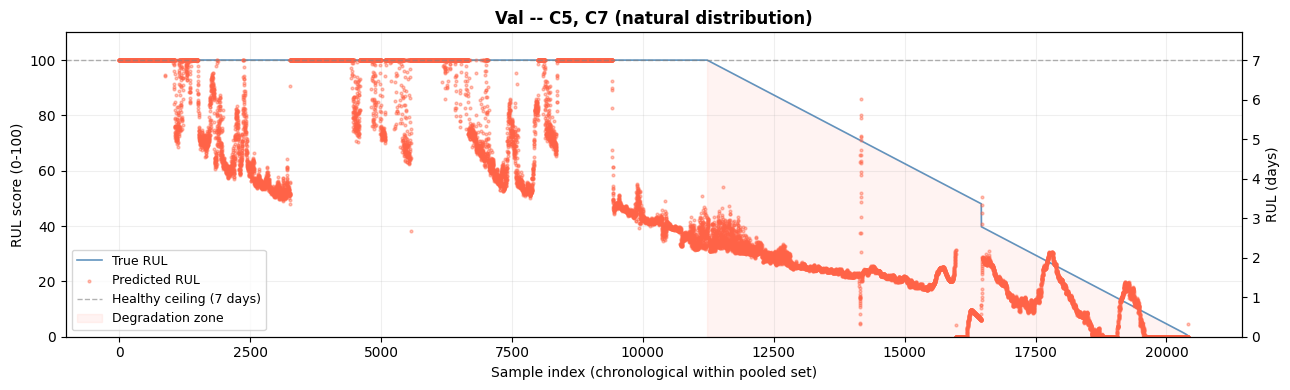

In [16]:
def plot_rul_predictions(y_true_score, y_pred_score, title, rul_clip_minutes):
    fig, ax = plt.subplots(figsize=(13, 4))

    ax.plot(y_true_score, color='steelblue', linewidth=1.2,
            alpha=0.85, label='True RUL')
    ax.scatter(range(len(y_pred_score)), y_pred_score,
               color='tomato', s=4, alpha=0.4,
               label='Predicted RUL', zorder=2)
    ax.axhline(y=100.0, color='gray', linestyle='--',
               linewidth=1.0, alpha=0.6, label='Healthy ceiling (7 days)')
    ax.fill_between(range(len(y_true_score)),
                    0, np.minimum(y_true_score, 100.0),
                    where=y_true_score < 100.0,
                    alpha=0.07, color='tomato', label='Degradation zone')

    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Sample index (chronological within pooled set)')
    ax.set_ylabel('RUL score (0-100)')
    ax.set_ylim(0, 110)

    ax_days = ax.twinx()
    ax_days.set_ylim(0, 110 * rul_clip_minutes / 60 / 24 / 100)
    ax_days.set_ylabel('RUL (days)')

    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()


plot_rul_predictions(y_train, y_pred_train, 'Train -- C2,C3,C4,C6,C8 (pooled, train-dev block excluded)', RUL_CLIP_MINUTES)
plot_rul_predictions(y_traindev, y_pred_traindev, 'Train-dev -- C2,C3,C4,C6,C8 (hourly 0-20min blocks)', RUL_CLIP_MINUTES)
plot_rul_predictions(y_val, y_pred_val, 'Val -- C5, C7 (natural distribution)', RUL_CLIP_MINUTES)

## Cell 13 — Error Distribution (Train-dev vs Val)

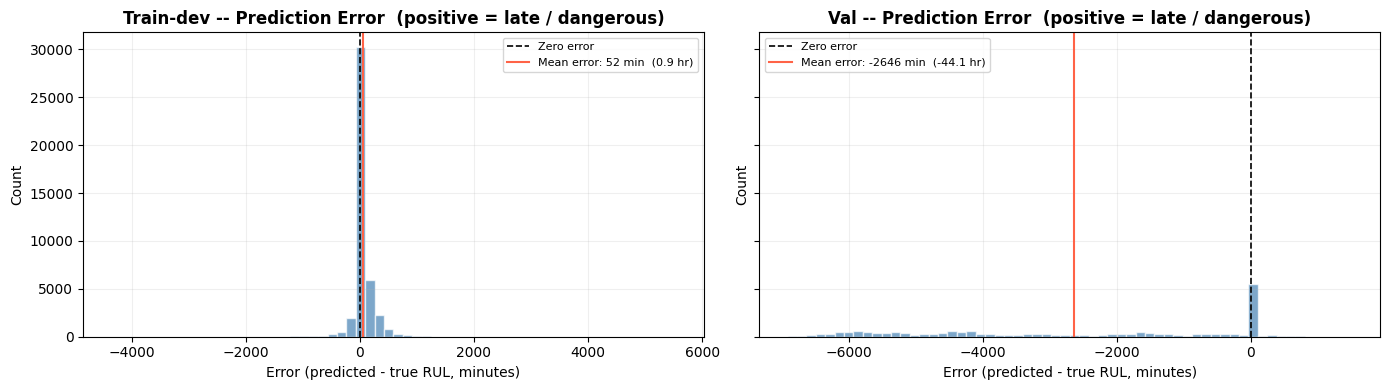

Train-dev -- Late: 33.3%  |  Early: 66.7%
Val       -- Late: 2.5%  |  Early: 97.5%


In [17]:
errors_traindev = (y_pred_traindev - y_traindev) * RUL_CLIP_MINUTES / 100.0
errors_val      = (y_pred_val - y_val) * RUL_CLIP_MINUTES / 100.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for ax, errors, title in [(ax1, errors_traindev, 'Train-dev'), (ax2, errors_val, 'Val')]:
    ax.hist(errors, bins=60, color='steelblue', alpha=0.7, edgecolor='white')
    ax.axvline(x=0, color='black', linestyle='--', linewidth=1.2, label='Zero error')
    ax.axvline(x=errors.mean(), color='tomato', linestyle='-', linewidth=1.5,
               label=f'Mean error: {errors.mean():.0f} min  ({errors.mean()/60:.1f} hr)')
    ax.set_title(f'{title} -- Prediction Error  (positive = late / dangerous)', fontweight='bold')
    ax.set_xlabel('Error (predicted - true RUL, minutes)')
    ax.set_ylabel('Count')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

print(f'Train-dev -- Late: {100*np.mean(errors_traindev > 0):.1f}%  |  Early: {100*np.mean(errors_traindev <= 0):.1f}%')
print(f'Val       -- Late: {100*np.mean(errors_val > 0):.1f}%  |  Early: {100*np.mean(errors_val <= 0):.1f}%')

## Cell 14 — Save Weights & Scaler

In [18]:
import joblib

SAVE_DIR = ''

# Lambda layer prevents load_model in TF 2.12 -- save weights only
model.save_weights(f'{SAVE_DIR}pipe_rul_v3_traindev.weights.h5')
joblib.dump(scaler, f'{SAVE_DIR}pipe_rul_v3_traindev_scaler.pkl')

print('Saved:')
print(f'  Weights : {SAVE_DIR}pipe_rul_v3_traindev.weights.h5')
print(f'  Scaler  : {SAVE_DIR}pipe_rul_v3_traindev_scaler.pkl')
print()
print('To reload:')
print('  model = build_model(WINDOW_SIZE, N_SENSORS, HIDDEN_UNITS)')
print('  model.load_weights(f"{SAVE_DIR}pipe_rul_v3_traindev.weights.h5")')
print('  scaler = joblib.load(f"{SAVE_DIR}pipe_rul_v3_traindev_scaler.pkl")')

Saved:
  Weights : pipe_rul_v3_traindev.weights.h5
  Scaler  : pipe_rul_v3_traindev_scaler.pkl

To reload:
  model = build_model(WINDOW_SIZE, N_SENSORS, HIDDEN_UNITS)
  model.load_weights(f"{SAVE_DIR}pipe_rul_v3_traindev.weights.h5")
  scaler = joblib.load(f"{SAVE_DIR}pipe_rul_v3_traindev_scaler.pkl")
